Device: cuda


Loading weights:   0%|          | 0/414 [00:00<?, ?it/s]

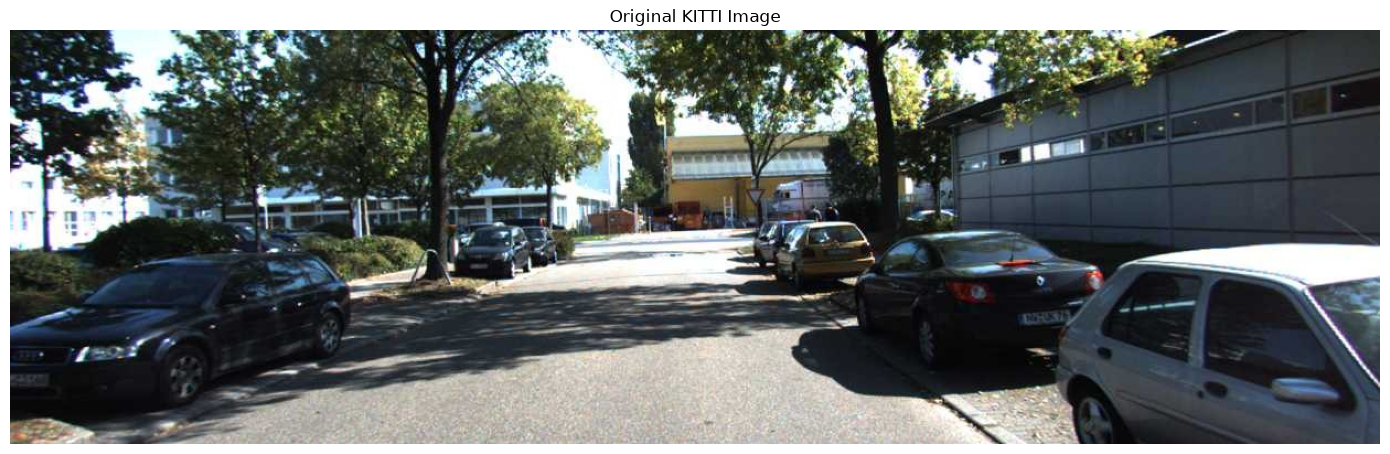

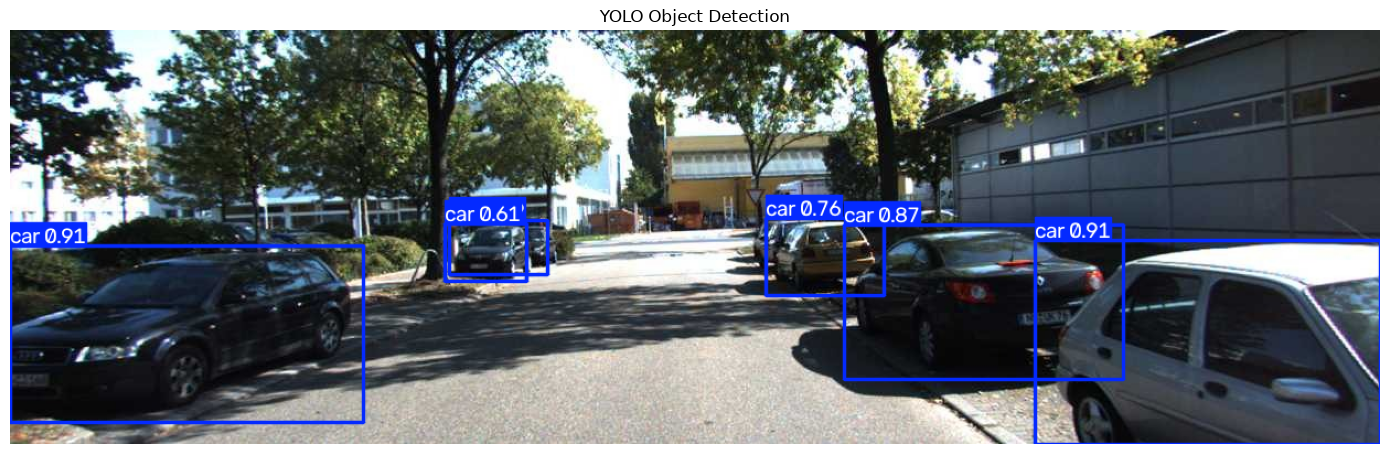

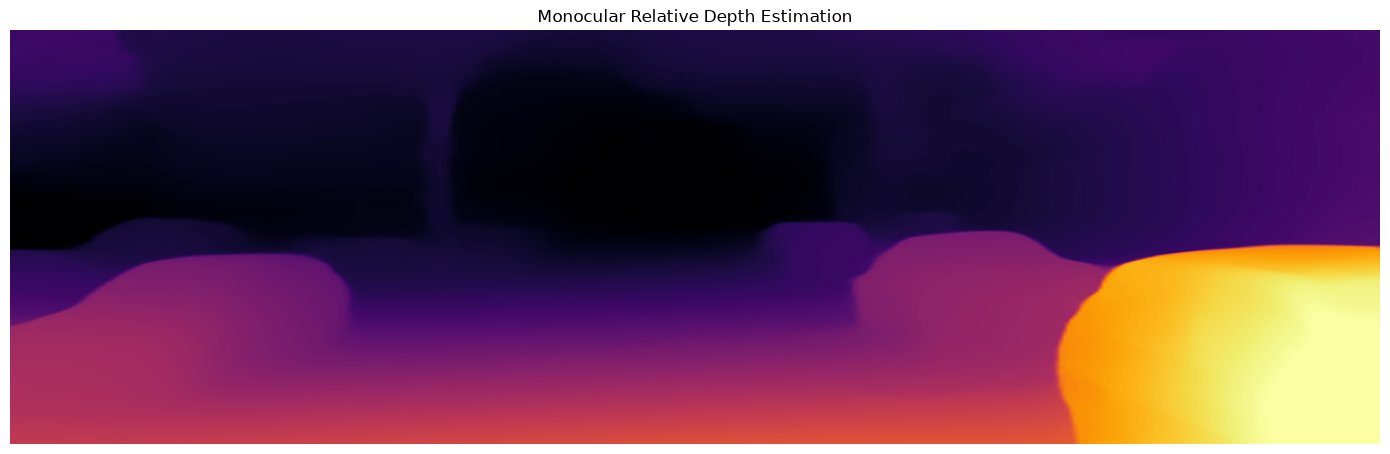

Detected objects: 6
Depth map shape: (375, 1242)


In [6]:

from pathlib import Path
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO
from transformers import DPTImageProcessor, DPTForDepthEstimation

# Project paths
project_dir = Path.cwd().parent
model_path = project_dir / "runs" / "kitti_improved" / "weights" / "best.pt"
val_dir = project_dir / "data" / "kitti_yolo" / "images" / "val"

image_path = val_dir / "000942.jpg"

assert model_path.exists(), f"YOLO model missing: {model_path}"
assert image_path.exists(), f"Image missing: {image_path}"

# Load image
image_bgr = cv2.imread(str(image_path))
if image_bgr is None:
    raise ValueError(f"Could not read {image_path}")

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
pil_image = Image.fromarray(image_rgb)

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Run YOLO
yolo_model = YOLO(str(model_path))
detection_results = yolo_model.predict(
    source=image_bgr,
    imgsz=416,
    conf=0.25,
    device=0 if device.type == "cuda" else "cpu",
    verbose=False
)

annotated_rgb = cv2.cvtColor(
    detection_results[0].plot(), cv2.COLOR_BGR2RGB
)

# Load depth model
depth_name = "Intel/dpt-hybrid-midas"
depth_processor = DPTImageProcessor.from_pretrained(depth_name)
depth_model = DPTForDepthEstimation.from_pretrained(depth_name)
depth_model = depth_model.to(device).eval()

depth_inputs = depth_processor(images=pil_image, return_tensors="pt")
depth_inputs = {k: v.to(device) for k, v in depth_inputs.items()}

with torch.no_grad():
    depth_outputs = depth_model(**depth_inputs)

depth_raw = torch.nn.functional.interpolate(
    depth_outputs.predicted_depth.unsqueeze(1),
    size=image_rgb.shape[:2],
    mode="bicubic",
    align_corners=False
).squeeze().cpu().numpy()

low, high = np.percentile(depth_raw, [2, 98])
depth_visual = np.clip(
    (depth_raw - low) / (high - low + 1e-8), 0, 1
)

# Display outputs separately, vertically
plt.figure(figsize=(14, 5))
plt.imshow(image_rgb)
plt.title("Original KITTI Image")
plt.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 5))
plt.imshow(annotated_rgb)
plt.title("YOLO Object Detection")
plt.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 5))
plt.imshow(depth_visual, cmap="inferno")
plt.title("Monocular Relative Depth Estimation")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Detected objects:", len(detection_results[0].boxes))
print("Depth map shape:", depth_raw.shape)
